In [2]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
S_0 = 1367      # [W/m2] solar constant at the mean Earth-Sun distance
lat = 50        # [deg] latitude
lon = 20        # [deg] longitude
lon_0 = 15      # [deg] reference meridian of my time zone
year = 2025     

phi = np.radians(lat)   



In [4]:
hours = pd.date_range(f"{year}-01-01 00:00", f"{year}-12-31 23:00", freq="h")  
df = pd.DataFrame(index=hours)
df["day"]  = df.index.dayofyear   
df["hour"] = df.index.hour        

print(len(df), "rows")
df.head()

8760 rows


,day,hour
2025-01-01 00:00:00,1,0
2025-01-01 01:00:00,1,1
2025-01-01 02:00:00,1,2
2025-01-01 03:00:00,1,3
2025-01-01 04:00:00,1,4


In [5]:
### top of the atmosphere ###

<Axes: xlabel='Day of the year', ylabel='Energy at top of atmosphere [W/m2]'>

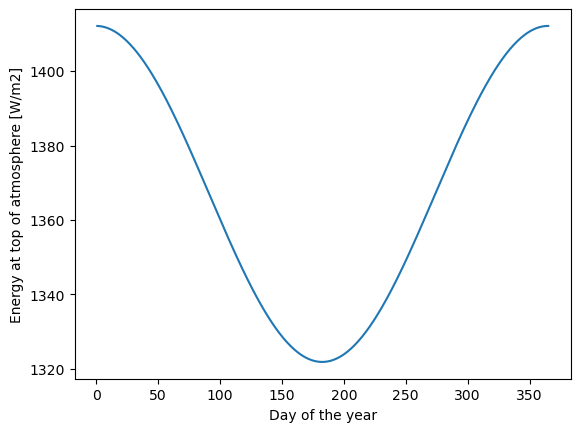

In [6]:
df["S_0d"] = S_0 * (1 + 0.033 * np.cos(2 * np.pi * df["day"] / 365))   # [W/m2]

df.groupby("day")["S_0d"].first().plot(xlabel="Day of the year", ylabel="Energy at top of atmosphere [W/m2]")

max decl: 23.44 deg on day 173
min decl: -23.46 deg on day 356


<Axes: xlabel='Day of the year', ylabel='Declination [deg]'>

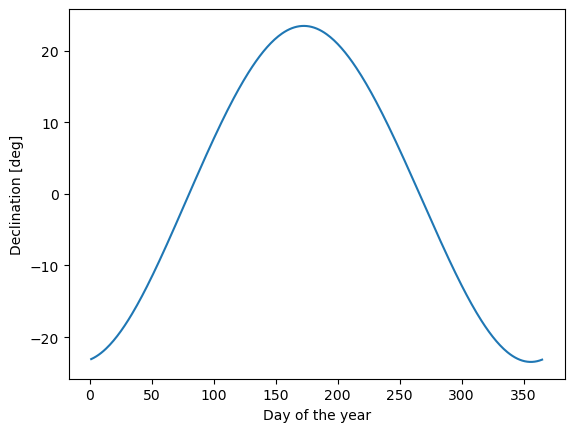

In [7]:
N = 2 * np.pi * df["day"] / 365

decl_deg = (0.33281
            - 22.984  * np.cos(N)     + 3.7872  * np.sin(N)
            - 0.3499  * np.cos(2 * N) + 0.03205 * np.sin(2 * N)
            - 0.1398  * np.cos(3 * N) + 0.07187 * np.sin(3 * N)) # [deg]

df["decl"] = np.radians(decl_deg) # [rad]

daily_decl = decl_deg.groupby(df["day"]).first()
print("max decl:", round(daily_decl.max(), 2), "deg on day", daily_decl.idxmax())
print("min decl:", round(daily_decl.min(), 2), "deg on day", daily_decl.idxmin())
daily_decl.plot(xlabel="Day of the year", ylabel="Declination [deg]")

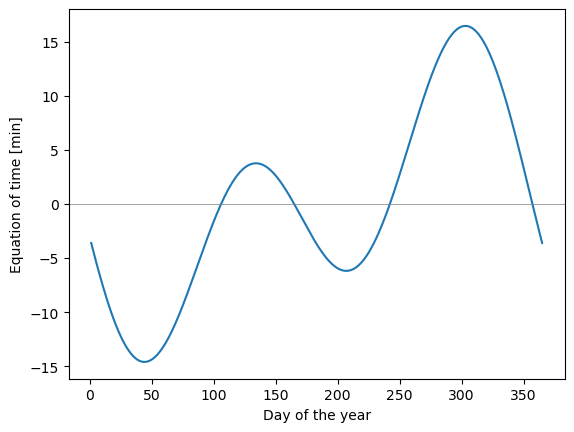

In [8]:
B = 2 * np.pi * (df["day"] - 81) / 364
eot = 9.87 * np.sin(2 * B) - 7.53 * np.cos(B) - 1.5 * np.sin(B) # equation of time [min]

df["eot"] = eot
df.groupby("day")["eot"].first().plot(xlabel="Day of the year", ylabel="Equation of time [min]")
plt.axhline(0, color="grey", lw=0.5);

In [9]:
correction_h = (4 * (lon - lon_0) + eot) / 60                     # solar time minus clock time [h]

df["tau_1"] = (df["hour"] + correction_h - 12) * 2 * np.pi / 24   # hour angle at start of the hour [rad]
df["tau_2"] = df["tau_1"] + 2 * np.pi / 24                        # hour angle at the end of the hour [rad]

In [10]:
tau_mid = (df["tau_1"] + df["tau_2"]) / 2 # Approximating the energy available during an hour, as the energy available in the middle of the hour

sin_h = np.sin(phi) * np.sin(df["decl"] + np.cos(phi) * np.cos(df["decl"] * np.cos(tau_mid)))
df["h"] = np.arcsin(sin_h) # Sun elevation [rad]
df["I_0h"] = df["S_0d"] * np.sin(df["h"])


In [11]:
cos_ts = (-np.tan(phi) * np.tan(df["decl"]))
df["tau_s"] = np.arccos(cos_ts) # sunset hour angle [rad]

t1 = df["tau_1"].clip(lower=-df["tau_s"], upper=df["tau_s"])
t2 = df["tau_2"].clip(lower=-df["tau_s"], upper=df["tau_s"])

E_joule = 86400 / (2 * np.pi) * df["S_0d"] * (
    (t2 - t1) * np.sin(phi) * np.sin(df["decl"])
    + np.cos(phi) * np.cos(df["decl"]) * (np.sin(t2) - np.sin(t1))
)                                                            # [J/m2]
df["E_hour"] = E_joule / 3600                                # [Wh/m2]


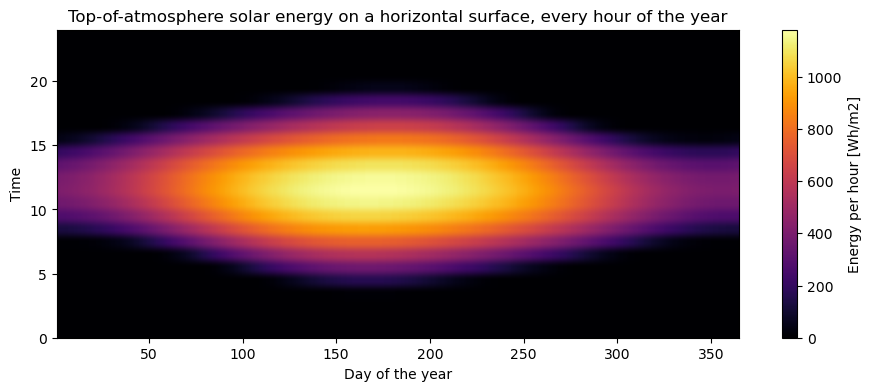

In [18]:
heat = df.pivot(index="hour", columns="day", values="E_hour")

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(heat, aspect="auto", origin="lower", extent=[1, 365, 0, 24], cmap="inferno")
fig.colorbar(im, label="Energy per hour [Wh/m2]")
ax.set_xlabel("Day of the year")
ax.set_ylabel("Time")
ax.set_title("Top-of-atmosphere solar energy on a horizontal surface, every hour of the year")
plt.show()